In [65]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 156
t = np.arange(n)

trend = 20 + 0.6 * t
tahunan = 12 * np.sin(2 * np.pi * t / 52 - 1.2)
semester = 6 * np.sin(4 * np.pi * t / 52 + 0.5)
noise = np.random.normal(0, 3, n)

reservasi = np.round(trend + tahunan + semester + noise).clip(min=0)

df = pd.DataFrame({
    'minggu': np.arange(1, n + 1),
    'tanggal': pd.date_range('2023-01-01', periods=n, freq='W'),
    'reservasi': reservasi
})
df.to_csv('venue_reservasi.csv', index=False)

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.deterministic import DeterministicProcess
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from xgboost import XGBRegressor

plt.rcParams['figure.figsize'] = (12, 5)

df = pd.read_csv('venue_reservasi.csv', parse_dates=['tanggal'], index_col='tanggal')
df = df.asfreq('W')

print(f"Ukuran data: {len(df)} baris")
print(f"Frekuensi indeks: {df.index.freq}")
print(df.head())

print("\nStatistik deskriptif:")
print(df['reservasi'].describe().round(1))

Ukuran data: 156 baris
Frekuensi indeks: <Week: weekday=6>
            minggu  reservasi
tanggal                      
2023-01-01       1       13.0
2023-01-08       2       14.0
2023-01-15       3       18.0
2023-01-22       4       23.0
2023-01-29       5       20.0

Statistik deskriptif:
count    156.0
mean      66.2
std       27.8
min       13.0
25%       42.5
50%       65.0
75%       90.2
max      118.0
Name: reservasi, dtype: float64


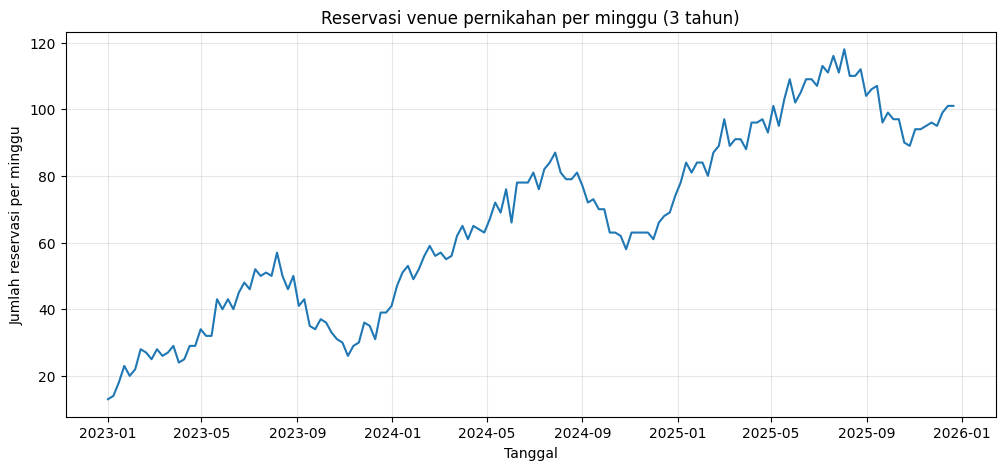

In [67]:
plt.plot(df.index, df['reservasi'], linewidth=1.5)
plt.xlabel('Tanggal')
plt.ylabel('Jumlah reservasi per minggu')
plt.title('Reservasi venue pernikahan per minggu (3 tahun)')
plt.grid(True, alpha=0.3)
plt.show()

In [68]:
# Split kronologis: 26 minggu terakhir (6 bulan) sebagai data uji
n_test = 26
train = df.iloc[:-n_test]
test = df.iloc[-n_test:]

print(f"Data latih: {len(train)} minggu (minggu 1 sampai {len(train)})")
print(f"Data uji: {len(test)} minggu (minggu {len(train) + 1} sampai {len(df)})")

Data latih: 130 minggu (minggu 1 sampai 130)
Data uji: 26 minggu (minggu 131 sampai 156)


In [69]:
# Fitur tren: konstanta (bias) + time dummy linear (orde 1)
dp = DeterministicProcess(index=train.index, constant=True, order=1, drop=True)

X_tren_train = dp.in_sample()
X_tren_test = dp.out_of_sample(steps=n_test)

print("Fitur tren data latih:")
print(X_tren_train.head())

Fitur tren data latih:
            const  trend
tanggal                 
2023-01-01    1.0    1.0
2023-01-08    1.0    2.0
2023-01-15    1.0    3.0
2023-01-22    1.0    4.0
2023-01-29    1.0    5.0


In [70]:
model_tren = LinearRegression()
model_tren.fit(X_tren_train, train['reservasi'])

pred_tren_train = model_tren.predict(X_tren_train)
pred_tren_test = model_tren.predict(X_tren_test)

print("Koefisien model tren:")
for nama, k in zip(X_tren_train.columns, model_tren.coef_):
    print(f"  {nama}: {k:.3f}")
print(f"Intercept: {model_tren.intercept_:.2f}")

Koefisien model tren:
  const: 0.000
  trend: 0.598
Intercept: 19.76


Statistik residual data latih:
count    130.00
mean      -0.00
std        9.36
min      -20.68
25%       -5.15
50%        0.36
75%        7.51
max       18.10
Name: reservasi, dtype: float64


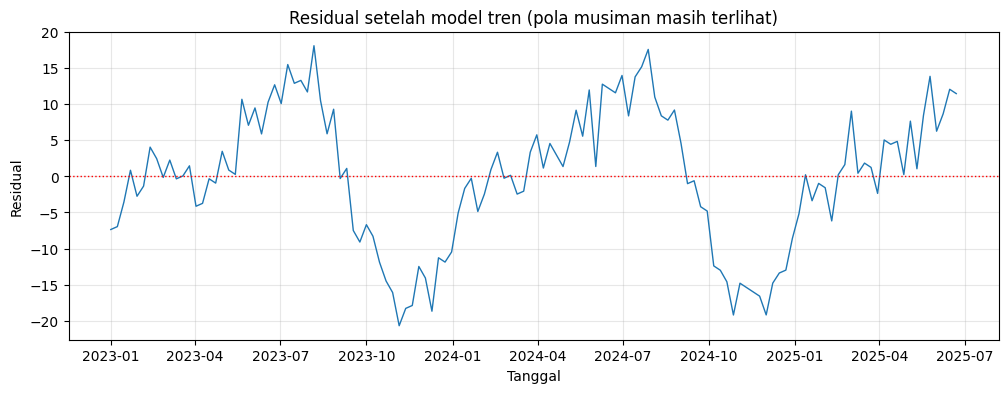

In [71]:
# Residual = aktual - prediksi tren
residual_train = train['reservasi'] - pred_tren_train
residual_test = test['reservasi'] - pred_tren_test

print("Statistik residual data latih:")
print(residual_train.describe().round(2))

plt.figure(figsize=(12, 4))
plt.plot(train.index, residual_train, linewidth=1)
plt.axhline(0, color='red', linestyle=':', linewidth=1)
plt.xlabel('Tanggal')
plt.ylabel('Residual')
plt.title('Residual setelah model tren (pola musiman masih terlihat)')
plt.grid(True, alpha=0.3)
plt.show()

In [73]:
def buat_fitur_musiman(idx):
    fitur = pd.DataFrame(index=idx)
    fitur['bulan'] = idx.month
    fitur['minggu_ke'] = idx.isocalendar().week.astype(int)
    return fitur

X_musim_train = buat_fitur_musiman(train.index)
X_musim_test = buat_fitur_musiman(test.index)

print("Fitur musiman data latih:")
print(X_musim_train.head())

Fitur musiman data latih:
            bulan  minggu_ke
tanggal                     
2023-01-01      1         52
2023-01-08      1          1
2023-01-15      1          2
2023-01-22      1          3
2023-01-29      1          4


In [74]:
model_sisa = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)
model_sisa.fit(X_musim_train, residual_train)

pred_sisa_test = model_sisa.predict(X_musim_test)

In [75]:
# Prediksi final = prediksi tren + prediksi residual
pred_hybrid_test = pred_tren_test + pred_sisa_test

mae_tren = mean_absolute_error(test['reservasi'], pred_tren_test)
mae_hybrid = mean_absolute_error(test['reservasi'], pred_hybrid_test)

print(f"MAE model tren saja: {mae_tren:.2f}")
print(f"MAE model hybrid: {mae_hybrid:.2f}")
print(f"Perbaikan: {((mae_tren - mae_hybrid) / mae_tren * 100):.1f}%")

MAE model tren saja: 11.30
MAE model hybrid: 2.20
Perbaikan: 80.5%


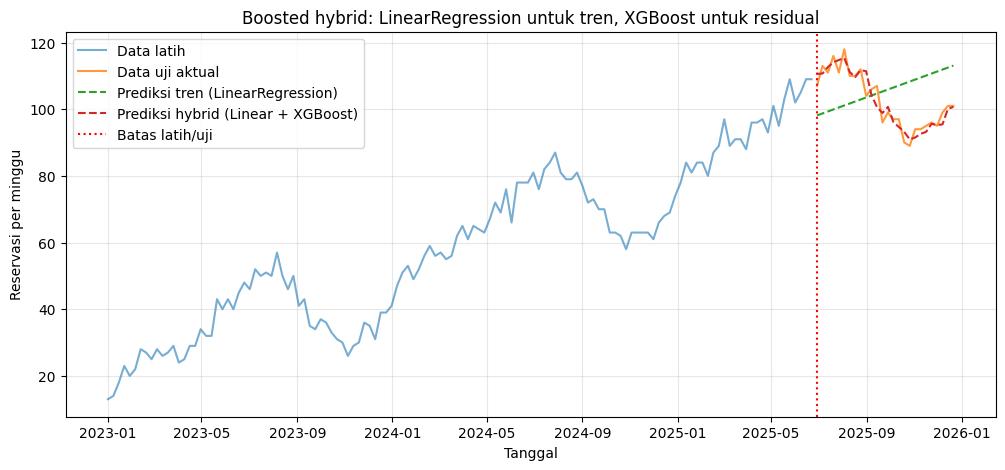

In [76]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train['reservasi'], label='Data latih', alpha=0.6)
plt.plot(test.index, test['reservasi'], label='Data uji aktual', alpha=0.8)
plt.plot(test.index, pred_tren_test, label='Prediksi tren (LinearRegression)', linestyle='--')
plt.plot(test.index, pred_hybrid_test, label='Prediksi hybrid (Linear + XGBoost)', linestyle='--')
plt.axvline(test.index[0], color='red', linestyle=':', label='Batas latih/uji')
plt.xlabel('Tanggal')
plt.ylabel('Reservasi per minggu')
plt.title('Boosted hybrid: LinearRegression untuk tren, XGBoost untuk residual')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [77]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5],
}

tscv = TimeSeriesSplit(n_splits=4)

pencari = GridSearchCV(
    XGBRegressor(random_state=42),
    param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

pencari.fit(X_musim_train, residual_train)
print("Parameter terbaik:", pencari.best_params_)

Parameter terbaik: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}


In [78]:
# Pakai model terbaik untuk prediksi final
model_sisa = pencari.best_estimator_
pred_sisa_test = model_sisa.predict(X_musim_test)
pred_hybrid_test = pred_tren_test + pred_sisa_test

mae_hybrid = mean_absolute_error(test['reservasi'], pred_hybrid_test)
print(f"MAE hybrid setelah tuning: {mae_hybrid:.2f}")

MAE hybrid setelah tuning: 2.05


In [79]:
n_forecast = 12  # meramal 12 minggu ke depan

# Lanjutkan tren dari akhir seluruh data (minggu 157-168)
X_tren_forecast = dp.out_of_sample(steps=n_test + n_forecast).iloc[-n_forecast:]
pred_tren_forecast = model_tren.predict(X_tren_forecast)

# Tanggal 12 minggu ke depan setelah data terakhir (minggu 156)
idx_forecast = pd.date_range(
    df.index[-1] + pd.Timedelta(days=7),
    periods=n_forecast,
    freq='W'
)
X_musim_forecast = buat_fitur_musiman(idx_forecast)
pred_sisa_forecast = model_sisa.predict(X_musim_forecast)

# Prediksi hybrid ke depan
pred_hybrid_forecast = pred_tren_forecast + pred_sisa_forecast

hasil_forecast = pd.DataFrame({
    'tanggal': idx_forecast,
    'reservasi_prediksi': pred_hybrid_forecast.round(1)
})
print("\nPeramalan 12 minggu ke depan:")
print(hasil_forecast)


Peramalan 12 minggu ke depan:
      tanggal  reservasi_prediksi
0  2025-12-28               104.5
1  2026-01-04               110.4
2  2026-01-11               113.4
3  2026-01-18               114.0
4  2026-01-25               114.6
5  2026-02-01               115.2
6  2026-02-08               117.0
7  2026-02-15               118.9
8  2026-02-22               119.5
9  2026-03-01               120.1
10 2026-03-08               120.7
11 2026-03-15               121.3


In [80]:
# Deviasi musiman = prediksi hybrid - prediksi tren
# Positif: minggu di atas garis tren (relatif ramai)
# Negatif: minggu di bawah garis tren (relatif sepi)

deviasi = pred_hybrid_forecast - pred_tren_forecast

hasil_forecast['prediksi_tren'] = pred_tren_forecast.round()
hasil_forecast['deviasi'] = deviasi.round(1)

print("Rincian peramalan:")
print(hasil_forecast)

print("\nRekomendasi operasional (berdasarkan deviasi dari tren):")
for i, row in hasil_forecast.iterrows():
    if row['deviasi'] < -2:
        label = "staf dikurangi"
    elif row['deviasi'] > 2:
        label = "staf ekstra"
    else:
        label = "staf normal"
    print(f"  {row['tanggal'].date()}: prediksi {row['reservasi_prediksi']:.1f}, "
          f"tren {row['prediksi_tren']:.1f}, deviasi {row['deviasi']:+.1f} -> {label}")

Rincian peramalan:
      tanggal  reservasi_prediksi  prediksi_tren  deviasi
0  2025-12-28               104.5          114.0     -9.2
1  2026-01-04               110.4          114.0     -3.9
2  2026-01-11               113.4          115.0     -1.5
3  2026-01-18               114.0          115.0     -1.5
4  2026-01-25               114.6          116.0     -1.5
5  2026-02-01               115.2          117.0     -1.5
6  2026-02-08               117.0          117.0     -0.3
7  2026-02-15               118.9          118.0      1.0
8  2026-02-22               119.5          118.0      1.0
9  2026-03-01               120.1          119.0      1.0
10 2026-03-08               120.7          120.0      1.0
11 2026-03-15               121.3          120.0      1.0

Rekomendasi operasional (berdasarkan deviasi dari tren):
  2025-12-28: prediksi 104.5, tren 114.0, deviasi -9.2 -> staf dikurangi
  2026-01-04: prediksi 110.4, tren 114.0, deviasi -3.9 -> staf dikurangi
  2026-01-11: prediksi 